## Step 0 - Create folder & check TensorFlow

In [1]:
import os
os.makedirs("dermassist", exist_ok=True)
import tensorflow as tf, cv2, streamlit
print("TF", tf.__version__, "| OpenCV", cv2.__version__, "| Streamlit", streamlit.__version__)

TF 2.21.0 | OpenCV 4.13.0 | Streamlit 1.58.0


## Step 1 - Write project files (run each cell once)

In [2]:
%%writefile dermassist/preprocess.py
"""Member 1 - Classical image processing:
hair removal, CLAHE, Otsu segmentation, ABCD features."""
import cv2
import numpy as np


def resize_max(img, max_side=512):
    h, w = img.shape[:2]
    s = max_side / max(h, w)
    if s >= 1:
        return img
    return cv2.resize(img, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)


def remove_hair(img_bgr):
    """Blackhat morphology finds dark hairs, inpainting fills them in."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (17, 17))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, hair_mask = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    hair_mask = cv2.dilate(hair_mask, np.ones((3, 3), np.uint8))
    clean = cv2.inpaint(img_bgr, hair_mask, 1, cv2.INPAINT_TELEA)
    return clean, hair_mask


def enhance_clahe(img_bgr):
    """CLAHE on the L channel of LAB colour space."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)


def segment_lesion(img_bgr):
    """Otsu threshold + morphology; keeps the main blob that does not touch the border."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (7, 7), 0)
    _, mask = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k)

    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    h, w = mask.shape
    cnts = [c for c in cnts if cv2.contourArea(c) >= 0.01 * h * w]
    if not cnts:
        return np.zeros_like(mask)

    def touches_border(c):
        x, y, bw, bh = cv2.boundingRect(c)
        return x <= 1 or y <= 1 or x + bw >= w - 1 or y + bh >= h - 1

    inner = [c for c in cnts if not touches_border(c)]
    best = max(inner or cnts, key=cv2.contourArea)
    clean = np.zeros_like(mask)
    cv2.drawContours(clean, [best], -1, 255, thickness=-1)  # filled, no holes
    return clean


def abcd_features(img_bgr, mask):
    """Asymmetry, Border irregularity, Colour variation, Diameter."""
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return None
    c = max(cnts, key=cv2.contourArea)
    area = cv2.contourArea(c)
    if area < 50:
        return None
    perimeter = cv2.arcLength(c, True)
    h, w = mask.shape

    # A - Asymmetry: align principal axis, flip, measure non-overlap
    m = cv2.moments(mask, binaryImage=True)
    cx, cy = m["m10"] / m["m00"], m["m01"] / m["m00"]
    theta = 0.5 * np.arctan2(2 * m["mu11"], m["mu20"] - m["mu02"])
    M = cv2.getRotationMatrix2D((cx, cy), float(np.degrees(theta)), 1.0)
    M[0, 2] += w / 2 - cx
    M[1, 2] += h / 2 - cy
    aligned = cv2.warpAffine(mask, M, (w, h), flags=cv2.INTER_NEAREST) > 0
    a = max(int(aligned.sum()), 1)
    asym_h = np.logical_xor(aligned, aligned[:, ::-1]).sum() / a
    asym_v = np.logical_xor(aligned, aligned[::-1, :]).sum() / a
    asymmetry = float((asym_h + asym_v) / 2)

    # B - Border irregularity: compactness (1.0 = perfect circle) and solidity
    compactness = float(perimeter ** 2 / (4 * np.pi * area))
    hull_area = cv2.contourArea(cv2.convexHull(c))
    solidity = float(area / hull_area) if hull_area > 0 else 1.0

    # C - Colour variation: spread in LAB + number of distinct colour clusters
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    px = lab[mask > 0].astype(np.float32)
    color_std = float(px.std(axis=0).mean())
    if len(px) > 5000:
        px = px[np.random.RandomState(0).choice(len(px), 5000, replace=False)]
    k = 6
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0)
    _, labels, centers = cv2.kmeans(px, k, None, crit, 3, cv2.KMEANS_PP_CENTERS)
    shares = np.bincount(labels.ravel(), minlength=k) / len(px)
    merged = []
    for i in range(k):
        if shares[i] >= 0.05 and all(np.linalg.norm(centers[i] - m_) > 25 for m_ in merged):
            merged.append(centers[i])
    n_colors = len(merged)

    # D - Diameter (pixels; real mm needs the camera scale, so also give it relative to image)
    diameter_px = float(np.sqrt(4 * area / np.pi))
    diameter_rel = diameter_px / max(h, w)

    flags = {
        "Asymmetry": asymmetry > 0.20,
        "Border irregular": compactness > 1.30,
        "Colour variation": n_colors >= 3,
        "Large diameter": diameter_rel > 0.40,
    }
    return {
        "asymmetry": round(asymmetry, 3),
        "compactness": round(compactness, 3),
        "solidity": round(solidity, 3),
        "color_std": round(color_std, 2),
        "n_colors": n_colors,
        "diameter_px": round(diameter_px, 1),
        "diameter_rel": round(diameter_rel, 3),
        "flags": flags,
        "abcd_score": int(sum(flags.values())),
    }


def analyze(img_bgr):
    """Full classical pipeline. Returns all intermediate images + ABCD features."""
    img = resize_max(img_bgr)
    clean, hair_mask = remove_hair(img)
    enhanced = enhance_clahe(clean)
    mask = segment_lesion(enhanced)
    overlay = enhanced.copy()
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(overlay, cnts, -1, (0, 255, 0), 2)
    feats = abcd_features(clean, mask)
    return {"original": img, "hair_mask": hair_mask, "clean": clean,
            "enhanced": enhanced, "mask": mask, "overlay": overlay, "features": feats}


Writing dermassist/preprocess.py


In [3]:
%%writefile dermassist/prepare_data.py
"""Builds data/train and data/val (benign / malignant) from the HAM10000 download.
Usage:  python prepare_data.py --raw PATH_TO_HAM10000_FOLDER
"""
import argparse, os, shutil
import pandas as pd
from sklearn.model_selection import train_test_split

MALIGNANT = {"mel", "bcc", "akiec"}   # everything else (nv, bkl, df, vasc) = benign

ap = argparse.ArgumentParser()
ap.add_argument("--raw", required=True, help="folder containing HAM10000 images + metadata csv")
ap.add_argument("--out", default=os.path.join(os.path.dirname(os.path.abspath(__file__)), "data"))
ap.add_argument("--max_benign", type=int, default=3000, help="cap benign train images (speed)")
ap.add_argument("--val", type=float, default=0.2)
args = ap.parse_args()

meta_path, paths = None, {}
for root, _, files in os.walk(args.raw):
    for f in files:
        if f.lower().startswith("ham10000_metadata") and f.lower().endswith(".csv"):
            meta_path = os.path.join(root, f)
        elif f.lower().endswith(".jpg"):
            paths[os.path.splitext(f)[0]] = os.path.join(root, f)
assert meta_path, "metadata csv not found inside --raw"
print("Found", len(paths), "images; metadata:", meta_path)

df = pd.read_csv(meta_path)
df = df[df.image_id.isin(paths)].copy()
df["label"] = df.dx.apply(lambda d: "malignant" if d in MALIGNANT else "benign")

# split by lesion_id so the same lesion never lands in both train and val
lesions = df.drop_duplicates("lesion_id")[["lesion_id", "label"]]
tr_l, _ = train_test_split(lesions, test_size=args.val, stratify=lesions.label, random_state=42)
df["split"] = df.lesion_id.isin(tr_l.lesion_id).map({True: "train", False: "val"})

ben_train = df[(df.split == "train") & (df.label == "benign")]
if len(ben_train) > args.max_benign:
    drop = ben_train.drop(ben_train.sample(args.max_benign, random_state=42).index).index
    df = df.drop(drop)

if os.path.exists(args.out):
    shutil.rmtree(args.out)
for _, r in df.iterrows():
    d = os.path.join(args.out, r.split, r.label)
    os.makedirs(d, exist_ok=True)
    shutil.copy(paths[r.image_id], d)

print(df.groupby(["split", "label"]).size())
print("Done ->", args.out)


Writing dermassist/prepare_data.py


In [4]:
%%writefile dermassist/train.py
"""Member 2 - MobileNetV2 transfer-learning classifier (benign vs malignant), TensorFlow/Keras."""
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

BASE = os.path.dirname(os.path.abspath(__file__))
DATA = os.path.join(BASE, "data")
MODEL_PATH = os.path.join(BASE, "dermassist_model.keras")
IMG, BATCH = 224, 32
EPOCHS_HEAD, EPOCHS_FINE = 6, 6

train_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DATA, "train"), image_size=(IMG, IMG), batch_size=BATCH,
    label_mode="binary", shuffle=True, seed=42)
val_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DATA, "val"), image_size=(IMG, IMG), batch_size=BATCH,
    label_mode="binary", shuffle=False)
print("Classes:", train_ds.class_names, "(sigmoid output = P(malignant))")

# class weights to handle imbalance
counts = [len(os.listdir(os.path.join(DATA, "train", c))) for c in train_ds.class_names]
total = sum(counts)
class_weight = {i: total / (len(counts) * n) for i, n in enumerate(counts)}
print("Train counts:", dict(zip(train_ds.class_names, counts)), "weights:", class_weight)

augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
])
train_ds = train_ds.map(lambda x, y: (augment(x, training=True), y),
                        num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False,
                                      weights="imagenet", name="base")
base.trainable = False
inp = keras.Input((IMG, IMG, 3))
x = layers.Rescaling(1 / 127.5, offset=-1, name="rescale")(inp)   # MobileNetV2 preprocessing
x = base(x, training=False)
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dropout(0.3, name="drop")(x)
out = layers.Dense(1, activation="sigmoid", name="out")(x)
model = keras.Model(inp, out)


def compile_model(lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc"),
                           keras.metrics.Recall(name="recall")])


cb = [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=3,
                                    restore_best_weights=True)]

print("\n--- Phase 1: train classification head ---")
compile_model(1e-3)
model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
          class_weight=class_weight, callbacks=cb, verbose=2)

print("\n--- Phase 2: fine-tune top layers ---")
base.trainable = True
for l in base.layers[:-30]:
    l.trainable = False
for l in base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False
compile_model(1e-5)
model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE,
          class_weight=class_weight, callbacks=cb, verbose=2)

model.save(MODEL_PATH)
print("Saved model ->", MODEL_PATH)

# final evaluation
y_true = np.concatenate([y.numpy() for _, y in val_ds]).ravel()
y_prob = model.predict(val_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)
print(classification_report(y_true, y_pred, target_names=["benign", "malignant"]))
print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))


Writing dermassist/train.py


In [5]:
%%writefile dermassist/gradcam.py
"""Member 3 - Grad-CAM explainability for the Keras model built in train.py."""
import cv2
import numpy as np
import tensorflow as tf


def gradcam_overlay(model, img_rgb, size=224, alpha=0.4):
    """img_rgb: uint8 RGB image. Returns (overlay_rgb, P(malignant))."""
    small = cv2.resize(img_rgb, (size, size)).astype("float32")
    x = model.get_layer("rescale")(tf.convert_to_tensor(small[None]))
    base, gap = model.get_layer("base"), model.get_layer("gap")
    drop, out = model.get_layer("drop"), model.get_layer("out")

    with tf.GradientTape() as tape:
        conv = base(x, training=False)
        tape.watch(conv)
        pred = out(drop(gap(conv), training=False))[:, 0]
    grads = tape.gradient(pred, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(conv * weights, axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    cam = cv2.resize(cam, (img_rgb.shape[1], img_rgb.shape[0]))
    heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(img_rgb, 1 - alpha, heat, alpha, 0)
    return overlay, float(pred.numpy()[0])


Writing dermassist/gradcam.py


In [6]:
%%writefile dermassist/app.py
"""Member 3 - Streamlit frontend for DermAssist."""
import os
import cv2
import numpy as np
import pandas as pd
import streamlit as st

from preprocess import analyze

BASE = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(BASE, "dermassist_model.keras")

st.set_page_config(page_title="DermAssist", page_icon="🩺", layout="wide")
st.title("🩺 DermAssist")
st.caption("Skin lesion screening: image processing + deep learning. "
           "Educational prototype - NOT a medical diagnosis.")


@st.cache_resource
def load_model():
    if not os.path.exists(MODEL_PATH):
        return None
    from tensorflow import keras
    return keras.models.load_model(MODEL_PATH)


model = load_model()
threshold = st.sidebar.slider("Malignant decision threshold", 0.1, 0.9, 0.5, 0.05)
st.sidebar.info("Lower threshold = more sensitive (catches more malignant cases, "
                "more false alarms).")
if model is None:
    st.sidebar.warning("No trained model found. Run train.py first. "
                       "Image-processing tabs still work.")

file = st.file_uploader("Upload a dermoscopic image", type=["jpg", "jpeg", "png"])
if file is None:
    st.info("Upload an image to begin.")
    st.stop()

img_bgr = cv2.imdecode(np.frombuffer(file.read(), np.uint8), cv2.IMREAD_COLOR)
if img_bgr is None:
    st.error("Could not read this image.")
    st.stop()

res = analyze(img_bgr)
rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

tab1, tab2, tab3 = st.tabs(["1. Preprocessing & Segmentation", "2. ABCD Analysis",
                            "3. AI Classification + Grad-CAM"])

with tab1:
    c = st.columns(4)
    c[0].image(rgb(res["original"]), caption="Original", width="stretch")
    c[1].image(rgb(res["clean"]), caption="Hair removed", width="stretch")
    c[2].image(rgb(res["enhanced"]), caption="CLAHE enhanced", width="stretch")
    c[3].image(rgb(res["overlay"]), caption="Otsu lesion boundary", width="stretch")
    st.image(res["mask"], caption="Segmentation mask", width=300)

with tab2:
    f = res["features"]
    if f is None:
        st.warning("No lesion could be segmented in this image.")
    else:
        m = st.columns(4)
        m[0].metric("Asymmetry", f["asymmetry"], help="0 = symmetric")
        m[1].metric("Border (compactness)", f["compactness"], help="1.0 = perfect circle")
        m[2].metric("Distinct colours", f["n_colors"])
        m[3].metric("Diameter (px)", f["diameter_px"])
        st.subheader(f"ABCD score: {f['abcd_score']} / 4 warning flags")
        st.table(pd.DataFrame({"Criterion": list(f["flags"].keys()),
                               "Flagged": ["⚠️ Yes" if v else "✅ No" for v in f["flags"].values()]}))
        st.caption("Thresholds are simple heuristics for demonstration.")
        with st.expander("All raw feature values"):
            st.json({k: v for k, v in f.items() if k != "flags"})

with tab3:
    if model is None:
        st.warning("Train the model first (train.py).")
    else:
        from gradcam import gradcam_overlay
        img_rgb = rgb(res["original"])
        overlay, p_mal = gradcam_overlay(model, img_rgb)
        is_mal = p_mal >= threshold
        conf = p_mal if is_mal else 1 - p_mal
        if is_mal:
            st.error(f"⚠️ Higher-risk lesion (malignant) - confidence {conf:.1%}")
        else:
            st.success(f"✅ Likely benign - confidence {conf:.1%}")
        st.progress(float(p_mal), text=f"P(malignant) = {p_mal:.3f}")
        c = st.columns(2)
        c[0].image(img_rgb, caption="Input", width="stretch")
        c[1].image(overlay, caption="Grad-CAM: regions driving the prediction", width="stretch")

st.divider()
st.caption("Always consult a qualified dermatologist for any skin concern.")


Writing dermassist/app.py


## Step 2 - Prepare dataset (HAM10000)
Download HAM10000 from Kaggle ("Skin Cancer MNIST: HAM10000") or ISIC, unzip it, and point `RAW` to the folder
containing the images and `HAM10000_metadata.csv` (sub-folders are fine).
Melanoma (`mel`), `bcc`, `akiec` -> **malignant**; the rest -> **benign**.

*Already have a dataset arranged as `train/benign`, `train/malignant`, `test/...`?* Skip this cell and just
copy it to `dermassist/data/train` and `dermassist/data/val`.

In [7]:
RAW = r"HAM10000"   # <-- edit this
!python dermassist/prepare_data.py --raw "{RAW}"

Found 10015 images; metadata: HAM10000\HAM10000_metadata.csv
split  label    
train  benign       3000
       malignant    1565
val    benign       1612
       malignant     389
dtype: int64
Done -> C:\Users\LOQ\OneDrive\Desktop\dermassist\data


## Step 3 - Train the classifier 
For a quick test, lower `EPOCHS_HEAD` / `EPOCHS_FINE` at the top of `train.py`.

In [8]:
!python dermassist/train.py

Found 4565 files belonging to 2 classes.
Found 2001 files belonging to 2 classes.
Classes: ['benign', 'malignant'] (sigmoid output = P(malignant))
Train counts: {'benign': 3000, 'malignant': 1565} weights: {0: 0.7608333333333334, 1: 1.4584664536741214}

      0/9406464 ==================== 0s 0s/step
  16384/9406464 ==================== 54s 6us/step
  40960/9406464 ==================== 36s 4us/step
  57344/9406464 ==================== 35s 4us/step
  90112/9406464 ==================== 28s 3us/step
 131072/9406464 ==================== 23s 2us/step
 196608/9406464 ==================== 17s 2us/step
 294912/9406464 ==================== 13s 1us/step
 409600/9406464 ==================== 10s 1us/step
 638976/9406464 ==================== 7s 1us/step 
 761856/9406464 ==================== 6s 1us/step
1228800/9406464 ==================== 4s 1us/step
1458176/9406464 ==================== 3s 0us/step
1916928/9406464 ==================== 2s 0us/step
2408448/9406464 ==================== 2s 0us/step
280

I0000 00:00:1794586136.424092    2228 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794586138.201857    2228 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794586141.703434    2228 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Step 4 - Quick test of the image-processing pipeline (no model needed)

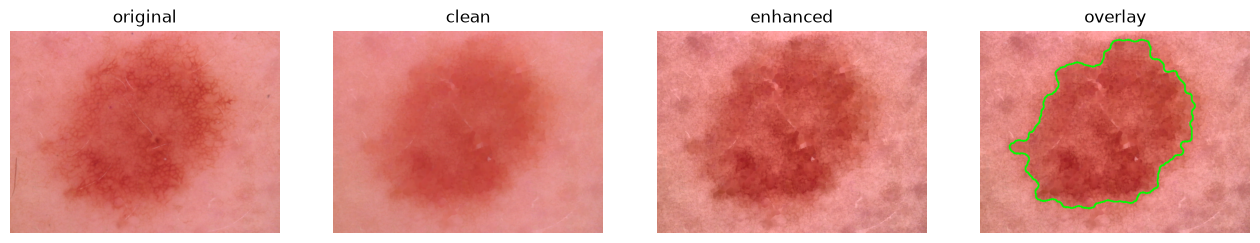

{'asymmetry': 0.152, 'compactness': 1.71, 'solidity': 0.899, 'color_std': 5.15, 'n_colors': 2, 'diameter_px': 304.6, 'diameter_rel': 0.595, 'flags': {'Asymmetry': False, 'Border irregular': True, 'Colour variation': False, 'Large diameter': True}, 'abcd_score': 2}


In [9]:
import sys, glob, cv2
import matplotlib.pyplot as plt
sys.path.insert(0, "dermassist")
from preprocess import analyze

path = glob.glob("dermassist/data/val/*/*.jpg")[0]      # or put any image path here
r = analyze(cv2.imread(path))
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, k in zip(ax, ["original", "clean", "enhanced", "overlay"]):
    a.imshow(cv2.cvtColor(r[k], cv2.COLOR_BGR2RGB)); a.set_title(k); a.axis("off")
plt.show()
print(r["features"])

## Step 5 - Launch the Streamlit app
Run this cell, then open **http://localhost:8501** in a new browser tab.
(If your Jupyter runs on a remote server, forward port 8501 or run `streamlit run app.py` from a terminal there.)

In [10]:
import subprocess, sys
app_proc = subprocess.Popen([sys.executable, "-m", "streamlit", "run", "app.py",
                             "--server.headless", "true", "--server.port", "8501"],
                            cwd="dermassist")
print("App starting -> open http://localhost:8501")
# To stop it later:  app_proc.terminate()

App starting -> open http://localhost:8501
